In [1]:
from getpass import getpass
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

engine = create_engine(URL.create(
    "postgresql+psycopg2", username="postgres",
    password=getpass("PostgreSQL password: "),
    host="localhost", port=5432, database="olist"))

def q(sql):
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

PostgreSQL password:  ········


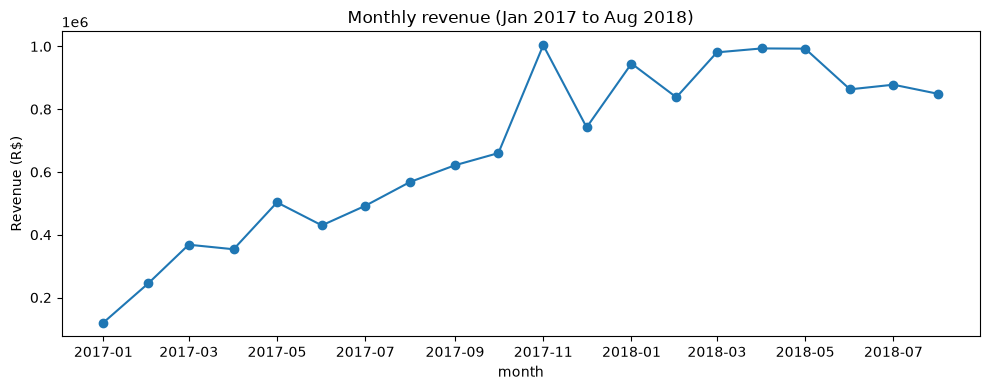

In [2]:
rev = q("""
SELECT date_trunc('month', o.order_purchase_timestamp)::date AS month,
       ROUND(SUM(oi.price), 2) AS revenue
FROM orders o JOIN order_items oi USING (order_id)
WHERE o.order_status NOT IN ('canceled', 'unavailable')
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
GROUP BY 1 ORDER BY 1
""")
ax = rev.plot(x="month", y="revenue", marker="o", legend=False, figsize=(10, 4))
ax.set_title("Monthly revenue (Jan 2017 to Aug 2018)")
ax.set_ylabel("Revenue (R$)")
plt.tight_layout()
plt.savefig("../dashboard/screenshots/monthly_revenue.png", dpi=150)
rev.to_csv("../data/processed/monthly_revenue.csv", index=False)

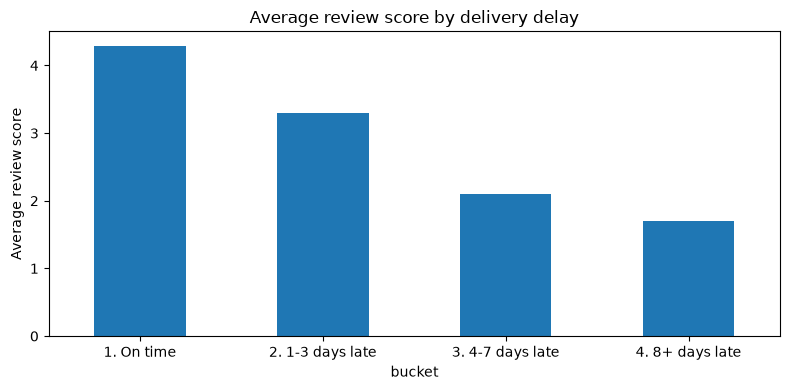

In [3]:
rev_delay = q("""
WITH latest_review AS (
    SELECT DISTINCT ON (order_id) order_id, review_score
    FROM order_reviews ORDER BY order_id, review_answer_timestamp DESC
),
delivered AS (
    SELECT order_id,
           (order_delivered_customer_date::date - order_estimated_delivery_date::date) AS d
    FROM orders
    WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
)
SELECT CASE WHEN d <= 0 THEN '1. On time' WHEN d <= 3 THEN '2. 1-3 days late'
            WHEN d <= 7 THEN '3. 4-7 days late' ELSE '4. 8+ days late' END AS bucket,
       ROUND(AVG(review_score), 2) AS avg_score
FROM delivered JOIN latest_review USING (order_id)
GROUP BY 1 ORDER BY 1
""")
ax = rev_delay.plot.bar(x="bucket", y="avg_score", legend=False, figsize=(8, 4), rot=0)
ax.set_title("Average review score by delivery delay")
ax.set_ylabel("Average review score")
plt.tight_layout()
plt.savefig("../dashboard/screenshots/review_vs_delay.png", dpi=150)